In [1]:
import numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F, copy, json
from pathlib import Path
from torch_geometric.data import HeteroData
from torch_geometric.nn import HGTConv
from sklearn.metrics import r2_score, mean_absolute_error
from scipy.stats import spearmanr

In [2]:
ROOT = Path(r"D:\Pancreatic_GraphTCDR"); P = ROOT/"data"/"processed"; T = P/"target_v2"
RES = ROOT/"results"/"v2"; RES.mkdir(parents=True, exist_ok=True)
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [3]:
train = pd.read_csv(T/"train_v2.csv"); val = pd.read_csv(T/"val_v2.csv"); test = pd.read_csv(T/"test_v2.csv")
assert len(train)==12929 and len(val)==1306 and len(test)==3802


In [4]:
cmap = pd.read_csv(P/"pancreatic28_cell_mapping.csv")
o2l = dict(zip(cmap["index"].astype(int), range(len(cmap))))
for d in (train, val, test): d["cell_local"] = d["omics_index"].map(o2l)
assert not any(d["cell_local"].isna().any() for d in (train, val, test))

In [5]:
ae = pd.read_csv(P/"pancreatic28_ae_embeddings_512.csv")
assert ae["cellLineName"].astype(str).tolist() == cmap["cellLineName"].astype(str).tolist()
cell_x = ae.drop(columns="cellLineName").to_numpy(np.float32)
cell_x = (cell_x - cell_x.mean(0)) / (cell_x.std(0) + 1e-6)     # label-free standardisation
drug_x = np.load(P/"drug_morgan_fingerprints_1228x2048.npy").astype(np.float32)

In [6]:
cell_adj = np.load(P/"pancreatic28_cell_adjacency_methylation_threshold075.npy")
drug_adj = np.load(P/"drug_adjacency_fingerprint_threshold075.npy")
ce = torch.tensor(np.vstack(np.where(cell_adj > 0)), dtype=torch.long)
de = torch.tensor(np.vstack(np.where(drug_adj > 0)), dtype=torch.long)


In [7]:
def build_graph(resp_pairs=None):
    """resp_pairs: DataFrame of TRAIN rows used for response edges, or None."""
    g = HeteroData()
    g["cell"].x = torch.tensor(cell_x); g["drug"].x = torch.tensor(drug_x)
    g["cell","similar","cell"].edge_index = ce
    g["drug","similar","drug"].edge_index = de
    if resp_pairs is not None and len(resp_pairs):
        e = []
        for _, grp in resp_pairs.groupby("drug_index"):
            k = max(1, int(np.ceil(len(grp) * 0.5)))
            e.append(grp.nsmallest(k, "y_clip"))
        e = pd.concat(e)
        ei = torch.tensor(np.vstack([e["cell_local"].to_numpy(np.int64), e["drug_index"].to_numpy(np.int64)]))
        g["cell","response","drug"].edge_index = ei
        g["drug","rev_response","cell"].edge_index = ei.flip(0)
    return g.to(dev)

print("loaded; cell edges", ce.shape[1], "drug edges", de.shape[1])

loaded; cell edges 482 drug edges 434


482 cell edges and 434 drug edges are the directed counts of your 241 and 217 undirected edges, so the graph pieces loaded as expected

model, minibatch training, variants A and B

In [9]:
class GTCDR(nn.Module):
    def __init__(s, metadata, h=256, heads=4, drop=0.3):
        super().__init__()
        s.cell_enc = nn.Sequential(nn.Linear(512, h), nn.ReLU(), nn.Dropout(drop))
        s.drug_enc = nn.Sequential(
            nn.Conv1d(1, 32, 9, padding=4), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(32, 64, 7, padding=3), nn.ReLU(), nn.AdaptiveAvgPool1d(1),
            nn.Flatten(), nn.Linear(64, h), nn.ReLU(), nn.Dropout(drop))
        s.layers = nn.ModuleList([HGTConv(h, h, metadata, heads=heads) for _ in range(3)])
        s.head = nn.Sequential(nn.Linear(2*h, 128), nn.ReLU(), nn.Dropout(drop), nn.Linear(128, 1))
    def encode(s, g):
        x = {"cell": s.cell_enc(g["cell"].x), "drug": s.drug_enc(g["drug"].x.unsqueeze(1))}
        for l in s.layers:
            out = l(x, g.edge_index_dict)
            x = {k: (F.relu(out[k]) if out.get(k) is not None else x[k]) for k in x}
        return x
    def pairs(s, z, c, d):
        return s.head(torch.cat([z["cell"][c], z["drug"][d]], 1)).squeeze(-1)

def T_(df):
    return (torch.tensor(df["cell_local"].to_numpy(np.int64), device=dev),
            torch.tensor(df["drug_index"].to_numpy(np.int64), device=dev),
            torch.tensor(df["y_clip"].to_numpy(np.float32), device=dev))

def run_graph(variant, seed, epochs=100, patience=15, bs=1024, lr=5e-4, wd=1e-3):
    torch.manual_seed(seed); np.random.seed(seed); rng = np.random.RandomState(seed)
    if variant == "A":                       # no response edges
        g = build_graph(None); loss_df = train
    else:                                    # B: edges from one half, loss on the other half
        idx = rng.permutation(len(train)); half = len(train) // 2
        E = train.iloc[idx[:half]]; loss_df = train.iloc[idx[half:]]
        assert set(E["drug_index"]).isdisjoint(set(val["drug_index"]) | set(test["drug_index"]))
        g = build_graph(E)
    model = GTCDR(g.metadata()).to(dev)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    tc, td, ty = T_(loss_df); vc, vd, vy = T_(val); sc, sd_, _ = T_(test)
    best, best_ep, state, bad = 1e9, 0, None, 0
    for ep in range(1, epochs + 1):
        model.train(); perm = torch.randperm(len(tc), device=dev)
        for i in range(0, len(perm), bs):
            j = perm[i:i+bs]
            z = model.encode(g)                              # graph re-encoded every step
            loss = F.mse_loss(model.pairs(z, tc[j], td[j]), ty[j])
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0); opt.step()
        model.eval()
        with torch.no_grad():
            z = model.encode(g); v = F.mse_loss(model.pairs(z, vc, vd), vy).item()
        if v < best: best, best_ep, bad, state = v, ep, 0, copy.deepcopy(model.state_dict())
        else:
            bad += 1
            if bad >= patience: break
    model.load_state_dict(state); model.eval()
    with torch.no_grad():
        z = model.encode(g); p = model.pairs(z, sc, sd_).cpu().numpy()
    return best, best_ep, p

yt = test["y_clip"].values
SEEDS = [42, 43, 44]         # run ONE seed first to check the time, then use [42, 43, 44]
for variant in ["A", "B"]:
    for s in SEEDS:
        v, ep, p = run_graph(variant, s)
        pd.DataFrame({"pred_clip": p}).to_csv(RES / f"pred_graph_{variant}_s{s}.csv", index=False)
        print(f"graph {variant} s{s} | best ep {ep} val {v:.4f} | test R2 {r2_score(yt,p):.4f} "
              f"MAE {mean_absolute_error(yt,p):.4f} rho {spearmanr(yt,p)[0]:.4f}")

graph A s42 | best ep 14 val 0.5882 | test R2 0.0416 MAE 0.5856 rho 0.2037
graph A s43 | best ep 19 val 0.5870 | test R2 0.0349 MAE 0.5881 rho 0.1848
graph A s44 | best ep 20 val 0.5872 | test R2 0.0351 MAE 0.5871 rho 0.1905
graph B s42 | best ep 12 val 0.6067 | test R2 0.1031 MAE 0.5845 rho 0.2229
graph B s43 | best ep 3 val 0.6184 | test R2 0.0059 MAE 0.6007 rho 0.1820
graph B s44 | best ep 1 val 0.6194 | test R2 -0.0035 MAE 0.6048 rho 0.1711


model with residual connection

In [10]:
class GTCDR_Res(GTCDR):
    def encode(s, g):
        x = {"cell": s.cell_enc(g["cell"].x), "drug": s.drug_enc(g["drug"].x.unsqueeze(1))}
        for l in s.layers:
            out = l(x, g.edge_index_dict)
            x = {k: (F.relu(out[k]) + x[k] if out.get(k) is not None else x[k]) for k in x}
        return x

training function (same as before, but chooses the model class)

In [11]:
def run_graph2(model_cls, seed, tag, epochs=100, patience=15, bs=1024, lr=5e-4, wd=1e-3, heads=4):
    torch.manual_seed(seed); np.random.seed(seed)
    g = build_graph(None)                                  # Variant A: no response edges
    model = model_cls(g.metadata(), heads=heads).to(dev)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    tc, td, ty = T_(train); vc, vd, vy = T_(val); sc, sd_, _ = T_(test)
    best, best_ep, state, bad = 1e9, 0, None, 0
    for ep in range(1, epochs + 1):
        model.train(); perm = torch.randperm(len(tc), device=dev)
        for i in range(0, len(perm), bs):
            j = perm[i:i+bs]
            z = model.encode(g)
            loss = F.mse_loss(model.pairs(z, tc[j], td[j]), ty[j])
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0); opt.step()
        model.eval()
        with torch.no_grad():
            z = model.encode(g); v = F.mse_loss(model.pairs(z, vc, vd), vy).item()
        if v < best: best, best_ep, bad, state = v, ep, 0, copy.deepcopy(model.state_dict())
        else:
            bad += 1
            if bad >= patience: break
    model.load_state_dict(state); model.eval()
    with torch.no_grad():
        z = model.encode(g); p = model.pairs(z, sc, sd_).cpu().numpy()
    pd.DataFrame({"pred_clip": p}).to_csv(RES / f"pred_graph_{tag}_s{seed}.csv", index=False)
    print(f"{tag} s{seed} | best ep {ep if False else best_ep} val {best:.4f} | test R2 {r2_score(yt,p):.4f} "
          f"MAE {mean_absolute_error(yt,p):.4f} rho {spearmanr(yt,p)[0]:.4f}")

yt = test["y_clip"].values
for s in [42, 43, 44]:
    run_graph2(GTCDR_Res, s, "A_res")

A_res s42 | best ep 20 val 0.5734 | test R2 0.0552 MAE 0.5793 rho 0.2391
A_res s43 | best ep 29 val 0.5752 | test R2 0.0515 MAE 0.5801 rho 0.2326
A_res s44 | best ep 26 val 0.5741 | test R2 0.0457 MAE 0.5795 rho 0.2295


16 heads

In [12]:
for s in [42, 43, 44]:
    run_graph2(GTCDR_Res, s, "A_res16", heads=16)

A_res16 s42 | best ep 38 val 0.5736 | test R2 0.0377 MAE 0.5839 rho 0.2072
A_res16 s43 | best ep 26 val 0.5756 | test R2 0.0454 MAE 0.5834 rho 0.2266
A_res16 s44 | best ep 29 val 0.5759 | test R2 0.0590 MAE 0.5809 rho 0.2479


In [13]:
# Cell 6: replace the Pearson drug graph with a Tanimoto kNN graph
X = drug_x
inter = X @ X.T
tan = inter / (X.sum(1)[:, None] + X.sum(1)[None, :] - inter + 1e-9)
np.fill_diagonal(tan, -1)
K = 5
nbr = np.argsort(-tan, axis=1)[:, :K]
src = np.repeat(np.arange(len(X)), K); dst = nbr.reshape(-1)
de = torch.tensor(np.vstack([np.concatenate([src, dst]), np.concatenate([dst, src])]), dtype=torch.long)
print("kNN drug edges:", de.shape[1])

kNN drug edges: 12280


In [14]:
# Cell 7: rerun the residual graph with the kNN drug graph
for s in [42, 43, 44]:
    run_graph2(GTCDR_Res, s, "A_res_knn")

A_res_knn s42 | best ep 10 val 0.5522 | test R2 0.0592 MAE 0.5730 rho 0.2585
A_res_knn s43 | best ep 18 val 0.5523 | test R2 0.0533 MAE 0.5758 rho 0.2584
A_res_knn s44 | best ep 11 val 0.5521 | test R2 0.0616 MAE 0.5738 rho 0.2612


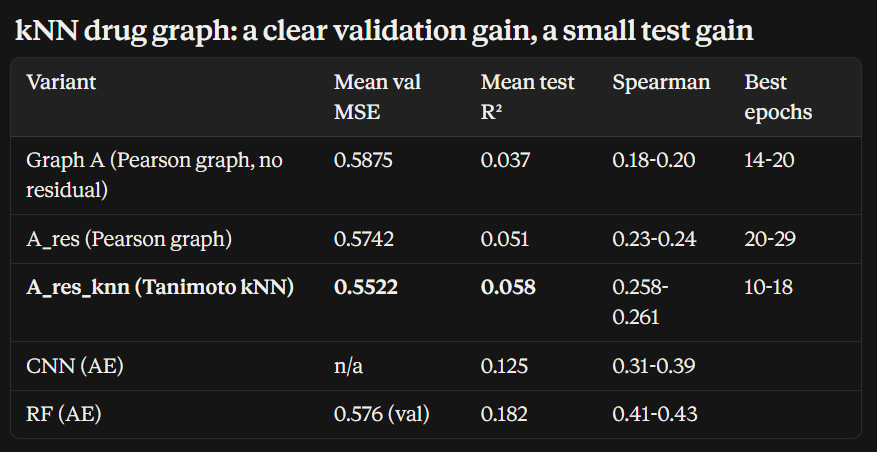

“Replacing the sparse Pearson drug graph with a Tanimoto kNN graph reduced validation error consistently and modestly improved test ranking, but the graph model remained well below Random Forest.”

In [18]:
RESULTS_DIR = RES          # D:\Pancreatic_GraphTCDR\results\v2
print(RESULTS_DIR)
print(sorted(p.name for p in RESULTS_DIR.glob("pred_rf_ae_*")))

D:\Pancreatic_GraphTCDR\results\v2
['pred_rf_ae_both_s42.csv', 'pred_rf_ae_both_s43.csv', 'pred_rf_ae_both_s44.csv', 'pred_rf_ae_qual_s42.csv', 'pred_rf_ae_qual_s43.csv', 'pred_rf_ae_qual_s44.csv', 'pred_rf_ae_s42.csv', 'pred_rf_ae_s43.csv', 'pred_rf_ae_s44.csv', 'pred_rf_ae_tail_s42.csv', 'pred_rf_ae_tail_s43.csv', 'pred_rf_ae_tail_s44.csv', 'pred_rf_ae_unw_s42.csv', 'pred_rf_ae_unw_s43.csv', 'pred_rf_ae_unw_s44.csv']


In [19]:
RESULTS_DIR = RES   # D:\Pancreatic_GraphTCDR\results\v2

bins = [-np.inf, -3, -1, 0, 1, 3, np.inf]
labels = ["< -3", "-3 to -1", "-1 to 0", "0 to 1", "1 to 3", "> 3"]
test["bin"] = pd.cut(test["y_raw"], bins=bins, labels=labels, right=False)
y = test["y_clip"].values

variants = ["unw", "qual", "tail", "both"]
P = {v: np.mean([pd.read_csv(RESULTS_DIR / f"pred_rf_ae_{v}_s{s}.csv")["pred_clip"].values
                 for s in [42, 43, 44]], 0) for v in variants}

rows = []
for v in variants:
    for b in labels:
        m = (test["bin"] == b).values
        rows.append({"variant": v, "bin": b, "n": int(m.sum()),
                     "MAE": np.mean(np.abs(y[m] - P[v][m])),
                     "bias": np.mean(P[v][m] - y[m])})
tab = pd.DataFrame(rows)

print("MAE vs y_clip by bin (rows = bin, cols = variant)")
print(tab.pivot(index="bin", columns="variant", values="MAE").loc[labels, variants].round(3))
print("\nMean bias (pred - actual); negative = under-prediction")
print(tab.pivot(index="bin", columns="variant", values="bias").loc[labels, variants].round(3))
print("\nBin counts")
print(test["bin"].value_counts().loc[labels])

# precision in the predicted most-sensitive 10% (random = 0.10)
k = int(0.10 * len(test))
true_low = set(np.argsort(test["y_raw"].values)[:k])
for v in variants:
    hit = len(true_low & set(np.argsort(P[v])[:k])) / k
    print(v, "precision in predicted most-sensitive 10%:", round(hit, 3), "(random = 0.10)")

MAE vs y_clip by bin (rows = bin, cols = variant)
variant     unw   qual   tail   both
bin                                 
< -3      2.748  2.723  2.697  2.691
-3 to -1  1.509  1.496  1.469  1.462
-1 to 0   0.441  0.437  0.414  0.411
0 to 1    0.319  0.323  0.349  0.350
1 to 3    1.029  1.040  1.069  1.066
> 3       1.122  1.147  1.195  1.191

Mean bias (pred - actual); negative = under-prediction
variant     unw   qual   tail   both
bin                                 
< -3      2.748  2.723  2.697  2.691
-3 to -1  1.509  1.496  1.469  1.461
-1 to 0   0.396  0.391  0.356  0.352
0 to 1   -0.273 -0.283 -0.314 -0.319
1 to 3   -1.029 -1.040 -1.069 -1.066
> 3      -1.122 -1.147 -1.195 -1.191

Bin counts
bin
< -3          44
-3 to -1     405
-1 to 0     1133
0 to 1      2166
1 to 3        39
> 3           15
Name: count, dtype: int64
unw precision in predicted most-sensitive 10%: 0.305 (random = 0.10)
qual precision in predicted most-sensitive 10%: 0.313 (random = 0.10)
tail precision in p

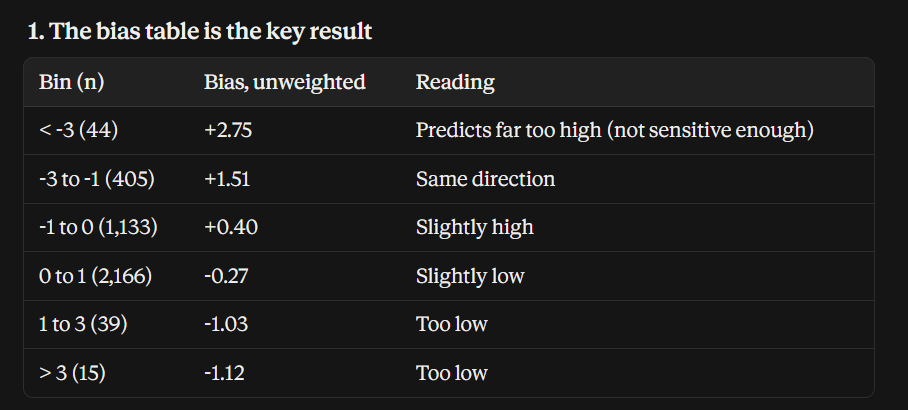

Every bin is pulled toward the centre. The more extreme the true value, the larger the error. This is regression to the mean, and it is exactly what a long-tailed target produces. MAE equals |bias| in the outer bins because the errors all go in one direction.

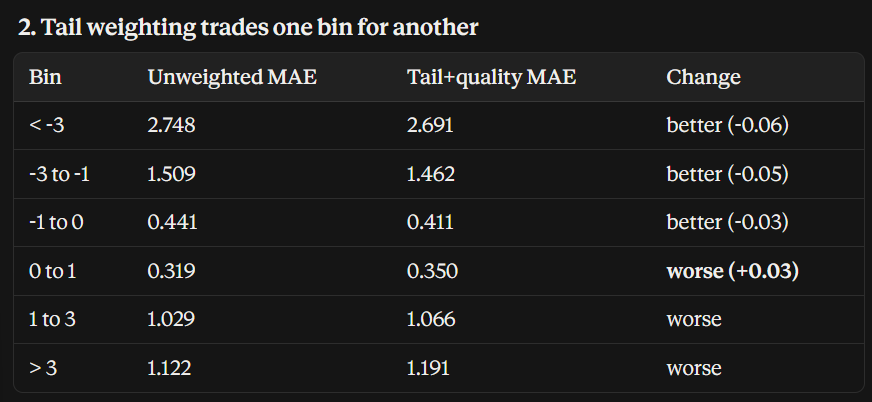

weighting redistributes error rather than removing the tail problem. Quality-only weighting barely moves anything (2.748 to 2.723).

The 0-to-1 bin holds 2,166 pairs, which is why overall R² still rose slightly despite that loss. Bins below -3 and above 3 have 44 and 15 pairs, so differences there are noisy.

The tail is about 1.5% of the data and its labels are mostly poorly fitted. All models, even with tail or quality weighting, shrink predictions toward the centre. Weighting shifts error between bins but does not fix extremes. Still, models enrich the most sensitive responses about 3-fold over chance, which is the screening-relevant use.